# NN_L6_topic_f1

**F1 per topic on the test tweets of the Twitter financial news topic data (20 classes): TF-IDF + logistic regression and an embedding bag with word2vec start.**

Neural Networks and Deep Learning (NN), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L6/NN_L6_topic_f1/NN_L6_topic_f1.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Per-class F1 on the published validation split, used as test.

macro-F1 TF-IDF + logistic (%) = 82.62   [topic.lr_f1]
macro-F1 embedding bag (%) = 80.45   [topic.eb_f1]


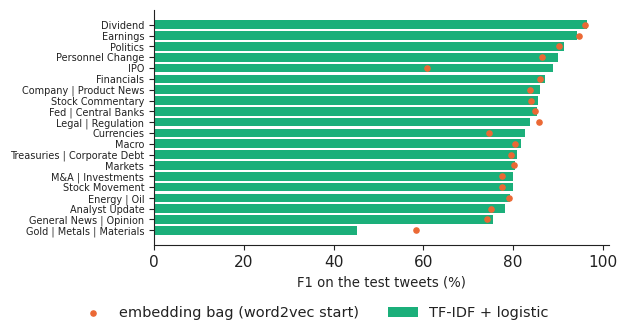

In [3]:
import json, urllib.request
_F = 'topic_f1_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L6/NN_L6_topic_f1/' + _F))
from sklearn.metrics import f1_score
y = np.array(R['y']); lr = np.array(R['lr']); eb = np.array(R['eb']); names = R['names']
show('topic.lr_f1', 'macro-F1 TF-IDF + logistic (%)', round(100 * f1_score(y, lr, average='macro'), 2)); show('topic.eb_f1', 'macro-F1 embedding bag (%)', round(100 * f1_score(y, eb, average='macro'), 2))
f1c = f1_score(y, lr, average=None); f1e = f1_score(y, eb, average=None); o = np.argsort(f1c)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.barh(range(20), 100 * f1c[o], color=PAL['benchmark'], label='TF-IDF + logistic'); ax.scatter(100 * f1e[o], range(20), color=PAL['model'], s=14, zorder=3, label='embedding bag (word2vec start)')
ax.set_yticks(range(20)); ax.set_yticklabels([names[i] for i in o], fontsize=7); ax.set_xlabel('F1 on the test tweets (%)', fontsize=9.5); legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, .08, 1, 1))
fig.savefig('topic_f1.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()